# TP2 · Predicción de la tasa de adopción de IA

**Pregunta:** ¿Qué tasa continua de adopción de IA puede estimarse para una empresa y trimestre a partir de país, industria, cantidad de empleados, ingresos, antigüedad y año?

## A. Marco experimental

ai_adoption_rate es un objetivo continuo que mide el nivel de adopción entre 0 y 100. Se excluyen ai_adoption_stage, derivada de la tasa, y las señales de comportamiento de adopción (herramientas usadas y capacitación); se conservan predictores de contexto para estimar el desempeño sin esas señales cercanas al objetivo.

La partición 80/20 separa empresas completas por company_id, con semilla 2026 para reproducibilidad. GroupKFold de cinco folds mantiene también separadas las empresas entre ajuste y validación.

## B. Modelos

Se comparan Dummy como piso de la media, LinearRegression como referencia lineal sin regularización, Ridge como referencia lineal regularizada, árbol y Random Forest. Las transformaciones se ajustan dentro de cada pipeline.

## C. Evaluación

La selección se basa en RMSE medio de validación agrupada; el hold-out queda reservado para la comparación final. Se informan MAE, MSE, R² y R² ajustado, además de diagnósticos de residuos, dispersión por tramos predichos y curva de aprendizaje.

In [1]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import normaltest
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

SEMILLA = 2026
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR_BASE, COLOR_LINEA = "#2b5c8f", "#d95f02"

DIRECTORIO = Path.cwd().resolve()
PROYECTO = DIRECTORIO if DIRECTORIO.name == "proyecto_equipo" else DIRECTORIO / "proyecto_equipo"
if not (PROYECTO / "notebooks").is_dir():
    raise FileNotFoundError("Abrí Jupyter desde la raíz del repositorio o desde proyecto_equipo")
RUTA_PARQUET = PROYECTO / "datos" / "derivados" / "ai_company_adoption_limpio.parquet"
if not RUTA_PARQUET.exists():
    raise FileNotFoundError("Ejecutá antes 02_limpieza_ai.ipynb para generar el Parquet limpio")
SALIDAS = PROYECTO / "salidas"
SALIDAS.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(RUTA_PARQUET)
assert df.shape == (150_000, 43), f"Dimensiones inesperadas: {df.shape}"
print(f"Dataset: {len(df):,} filas | {df['company_id'].nunique():,} empresas | datos derivados del proyecto")

Dataset: 150,000 filas | 10,000 empresas | datos derivados del proyecto


In [2]:
# Objetivo continuo: tasa de adopción de IA, expresada entre 0 y 100.
objetivo = "ai_adoption_rate"
columnas_categoricas = ["country", "industry"]
columnas_log = ["num_employees", "annual_revenue_usd_millions"]
columnas_escaladas = ["company_age", "survey_year"]
predictores = columnas_log + columnas_escaladas + columnas_categoricas

# Excluimos el identificador y las variables derivadas del objetivo o medidas al mismo tiempo
# que podrían no estar disponibles al estimar adopción (incluida ai_adoption_stage).
X = df[predictores].copy()
y = pd.to_numeric(df[objetivo], errors="raise").astype(float)
grupos = df["company_id"].astype("string")

# Hold-out agrupado: las filas de cada empresa quedan juntas.
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
train_idx, test_idx = next(gss.split(X, y, groups=grupos))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
grupos_train, grupos_test = grupos.iloc[train_idx], grupos.iloc[test_idx]
assert set(grupos_train).isdisjoint(set(grupos_test))
print(f"Entrenamiento: {len(X_train):,} filas / {grupos_train.nunique():,} empresas")
print(f"Prueba: {len(X_test):,} filas / {grupos_test.nunique():,} empresas; empresas compartidas: 0")

Entrenamiento: 119,969 filas / 8,000 empresas
Prueba: 30,031 filas / 2,000 empresas; empresas compartidas: 0


In [3]:
# Cada modelo recibe su propio preprocesador para evitar estado compartido entre pipelines.
def crear_preprocesador():
    preparador_log = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("escalar", StandardScaler()),
    ])
    preparador_escalado = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    preparador_categorico = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num_log", preparador_log, columnas_log),
        ("num_std", preparador_escalado, columnas_escaladas),
        ("cat", preparador_categorico, columnas_categoricas),
    ], remainder="drop")

In [4]:
# Dummy es el piso; LinearRegression y Ridge son referencias lineales.
pipe_dummy = Pipeline([("modelo", DummyRegressor(strategy="mean"))])
pipe_linear = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", LinearRegression()),
])
cv_agrupado = GroupKFold(n_splits=5)
grilla_alpha = [0.001, 0.01, 0.1, 1, 10, 25, 50, 100, 200, 350, 500, 1_000, 2_500, 5_000, 10_000]
pipe_ridge = Pipeline([("prepro", crear_preprocesador()), ("modelo", Ridge())])
grid_ridge = GridSearchCV(pipe_ridge, param_grid={"modelo__alpha": grilla_alpha}, cv=cv_agrupado,
                          scoring="neg_root_mean_squared_error", n_jobs=1, return_train_score=True, refit=True)
grid_ridge.fit(X_train, y_train, groups=grupos_train)
mejor_ridge = grid_ridge.best_estimator_
print(f"Mejor alpha Ridge: {grid_ridge.best_params_['modelo__alpha']}")
print(f"RMSE medio de Ridge en GroupKFold: {-grid_ridge.best_score_:.3f} puntos")

# Árbol limitado en profundidad y tamaño de hoja para controlar su varianza.
pipe_tree = Pipeline([("prepro", crear_preprocesador()),
                      ("modelo", DecisionTreeRegressor(max_depth=6, min_samples_leaf=50, random_state=SEMILLA))])
# Bosque base y grilla pequeña para contrastar hojas y profundidad como estrategias contra sobreajuste.
pipe_rf = Pipeline([("prepro", crear_preprocesador()),
                    ("modelo", RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=20,
                                                     random_state=SEMILLA, n_jobs=1))])
grilla_rf = GridSearchCV(pipe_rf,
    param_grid={"modelo__max_depth": [6, 10]},
    cv=cv_agrupado, scoring="neg_root_mean_squared_error", n_jobs=1, return_train_score=True, refit=True)
grilla_rf.fit(X_train, y_train, groups=grupos_train)
pipe_rf_ajustado = grilla_rf.best_estimator_
print(f"RF ajustado: {grilla_rf.best_params_}; RMSE CV de búsqueda={-grilla_rf.best_score_:.3f}")
idx_rf = grilla_rf.best_index_
tabla_ajuste_rf = pd.DataFrame([{
    "Profundidad": grilla_rf.best_params_["modelo__max_depth"],
    "RMSE train CV medio": -grilla_rf.cv_results_["mean_train_score"][idx_rf],
    "RMSE validación CV medio": -grilla_rf.cv_results_["mean_test_score"][idx_rf],
    "Tiempo ajuste medio por fold (s)": grilla_rf.cv_results_["mean_fit_time"][idx_rf],
}])
display(tabla_ajuste_rf.round(3))
tabla_ajuste_rf.to_csv(SALIDAS / "ajuste_random_forest_tp2.csv", index=False)

scoring_reg = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
cv_estimadores = {"Baseline (media)": pipe_dummy, "LinearRegression": pipe_linear,
                  "Árbol de decisión": pipe_tree, "Random Forest": pipe_rf}
resultados_cv = {}
for nombre, estimador in cv_estimadores.items():
    resultados_cv[nombre] = cross_validate(estimador, X_train, y_train, groups=grupos_train,
        cv=cv_agrupado, scoring=scoring_reg, return_train_score=True, n_jobs=1)

idx_alpha = grid_ridge.best_index_
n_folds = cv_agrupado.get_n_splits(X_train, y_train, grupos_train)
resultados_cv["Ridge"] = {
    "test_RMSE": np.array([grid_ridge.cv_results_[f"split{i}_test_score"][idx_alpha] for i in range(n_folds)]),
    "train_RMSE": np.array([grid_ridge.cv_results_[f"split{i}_train_score"][idx_alpha] for i in range(n_folds)]),
}
cv_ridge_fijo = cross_validate(mejor_ridge, X_train, y_train, groups=grupos_train, cv=cv_agrupado,
    scoring=scoring_reg, return_train_score=True, n_jobs=1)
resultados_cv["Ridge"].update({k: cv_ridge_fijo[k] for k in ["test_MAE", "train_MAE", "test_R2", "train_R2", "fit_time"]})

filas_cv = []
for nombre, r in resultados_cv.items():
    test_rmse, train_rmse = -r["test_RMSE"], -r["train_RMSE"]
    test_mae, train_mae = -r["test_MAE"], -r["train_MAE"]
    test_r2, train_r2 = r["test_R2"], r["train_R2"]
    filas_cv.append({"Modelo": nombre,
        "RMSE CV (media ± DE)": f"{test_rmse.mean():.3f} ± {test_rmse.std(ddof=1):.3f}",
        "MAE CV (media ± DE)": f"{test_mae.mean():.3f} ± {test_mae.std(ddof=1):.3f}",
        "R² CV (media ± DE)": f"{test_r2.mean():.3f} ± {test_r2.std(ddof=1):.3f}",
        "Tiempo ajuste CV (s)": f"{r['fit_time'].mean():.2f} ± {r['fit_time'].std(ddof=1):.2f}",
        "RMSE train CV (media)": round(train_rmse.mean(), 3),
        "RMSE validación CV (media)": round(test_rmse.mean(), 3),
        "Brecha RMSE CV": round(test_rmse.mean() - train_rmse.mean(), 3),
        "RMSE CV media numérica": test_rmse.mean()})
df_cv_modelos = pd.DataFrame(filas_cv).sort_values("RMSE CV media numérica")
display(df_cv_modelos.drop(columns="RMSE CV media numérica"))
df_cv_modelos.drop(columns="RMSE CV media numérica").to_csv(SALIDAS / "validacion_cruzada_tp2.csv", index=False)

# El hold-out solo se utiliza para la comparación final; GridSearchCV ya ajustó el RF ganador en train.
for modelo in [pipe_dummy, pipe_linear, pipe_tree, pipe_rf]:
    modelo.fit(X_train, y_train)
print("Modelos listos; la selección se hará por RMSE medio de CV, no mirando el test.")

Mejor alpha Ridge: 200
RMSE medio de Ridge en GroupKFold: 13.793 puntos
RF ajustado: {'modelo__max_depth': 6}; RMSE CV de búsqueda=13.789


,Profundidad,RMSE train CV medio,RMSE validación CV medio,Tiempo ajuste medio por fold (s)
0,6,13.636,13.789,8.621


,Modelo,RMSE CV (media ± DE),MAE CV (media ± DE),R² CV (media ± DE),Tiempo ajuste CV (s),RMSE train CV (media),RMSE validación CV (media),Brecha RMSE CV
4,Ridge,13.793 ± 0.128,11.057 ± 0.098,0.098 ± 0.005,0.08 ± 0.01,13.747,13.793,0.046
1,LinearRegression,13.795 ± 0.125,11.059 ± 0.097,0.097 ± 0.005,0.12 ± 0.00,13.745,13.795,0.050
3,Random Forest,13.798 ± 0.126,11.061 ± 0.098,0.097 ± 0.008,13.52 ± 0.43,13.282,13.798,0.516
2,Árbol de decisión,13.850 ± 0.139,11.098 ± 0.106,0.090 ± 0.008,0.21 ± 0.01,13.693,13.850,0.157
0,Baseline (media),14.525 ± 0.111,11.639 ± 0.073,-0.001 ± 0.000,0.00 ± 0.00,14.524,14.525,0.001


Modelos listos; la selección se hará por RMSE medio de CV, no mirando el test.


In [5]:
def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_te, y_te):
    pred_tr = modelo.predict(X_tr)
    pred_te = modelo.predict(X_te)
    mse_tr, mse_te = mean_squared_error(y_tr, pred_tr), mean_squared_error(y_te, pred_te)
    p = len(modelo.named_steps["prepro"].get_feature_names_out()) if "prepro" in modelo.named_steps else 0
    def r2_ajustado(y_real, y_hat, p):
        n = len(y_real)
        if n <= p + 1:
            return np.nan
        r2 = r2_score(y_real, y_hat)
        return 1 - (1 - r2) * (n - 1) / (n - p - 1)
    def mape_sin_ceros(y_real, y_hat):
        y_real = np.asarray(y_real, dtype=float)
        y_hat = np.asarray(y_hat, dtype=float)
        mask = y_real != 0
        if not mask.any():
            return np.nan
        return np.mean(np.abs((y_real[mask] - y_hat[mask]) / y_real[mask])) * 100
    def wape(y_real, y_hat):
        denom = np.sum(np.abs(np.asarray(y_real, dtype=float)))
        return np.sum(np.abs(np.asarray(y_real, dtype=float) - np.asarray(y_hat, dtype=float))) / denom * 100 if denom else np.nan
    return {
        "Modelo": nombre,
        "Predictores transformados": p,
        "MSE (Train)": round(mse_tr, 3), "MSE (Test)": round(mse_te, 3),
        "RMSE (Train)": round(np.sqrt(mse_tr), 3), "RMSE (Test)": round(np.sqrt(mse_te), 3),
        "MAE (Train)": round(mean_absolute_error(y_tr, pred_tr), 3), "MAE (Test)": round(mean_absolute_error(y_te, pred_te), 3),
        "R² (Train)": round(r2_score(y_tr, pred_tr), 3), "R² (Test)": round(r2_score(y_te, pred_te), 3),
        "R² ajustado (Train)": round(r2_ajustado(y_tr, pred_tr, p), 3),
        "R² ajustado (Test)": round(r2_ajustado(y_te, pred_te, p), 3),
        "MAPE Train sin y=0 (%)": round(mape_sin_ceros(y_tr, pred_tr), 3),
        "MAPE Test sin y=0 (%)": round(mape_sin_ceros(y_te, pred_te), 3),
        "WAPE (Test, %)": round(wape(y_te, pred_te), 3),
        "Brecha RMSE": round(np.sqrt(mse_te) - np.sqrt(mse_tr), 3),
    }

modelos = [
    ("Baseline (media)", pipe_dummy), ("LinearRegression", pipe_linear), ("Ridge", mejor_ridge),
    ("Árbol de decisión", pipe_tree), ("Random Forest", pipe_rf),
    ("Random Forest (ajustado)", pipe_rf_ajustado),
]
df_comparativa = pd.DataFrame([
    evaluar_modelo(nombre, modelo, X_train, y_train, X_test, y_test)
    for nombre, modelo in modelos
])
# ai_adoption_rate contiene ceros: el MAPE se informa solo para y != 0 y se declara cuántos se excluyen.
ceros_train, ceros_test = int((y_train == 0).sum()), int((y_test == 0).sum())
print(f"Objetivo igual a cero: train={ceros_train:,}, test={ceros_test:,}; esas filas se excluyen del MAPE. WAPE se calcula sobre todas.")
display(df_comparativa)
df_comparativa.to_csv(SALIDAS / "tabla_comparativa_modelos_tp2.csv", index=False)

# Selección metodológica por validación cruzada; el test queda solo como evaluación final.
modelos_por_nombre = dict(modelos)
cv_no_baseline = df_cv_modelos[df_cv_modelos["Modelo"] != "Baseline (media)"]
mejor_nombre = cv_no_baseline.sort_values("RMSE CV media numérica").iloc[0]["Modelo"]
modelo_seleccionado = modelos_por_nombre[mejor_nombre]
print(f"Modelo seleccionado por menor RMSE medio de GroupKFold: {mejor_nombre}")

Objetivo igual a cero: train=705, test=191; esas filas se excluyen del MAPE. WAPE se calcula sobre todas.


,Modelo,Predictores transformados,MSE (Train),MSE (Test),RMSE (Train),RMSE (Test),MAE (Train),MAE (Test),R² (Train),R² (Test),R² ajustado (Train),R² ajustado (Test),MAPE Train sin y=0 (%),MAPE Test sin y=0 (%),"WAPE (Test, %)",Brecha RMSE
0,Baseline (media),0,210.946,213.863,14.524,14.624,11.638,11.716,0.000,-0.000,0.000,-0.000,76.155,71.375,32.277,0.100
1,LinearRegression,41,189.060,192.942,13.750,13.890,11.024,11.135,0.104,0.098,0.103,0.097,70.499,66.547,30.676,0.140
2,Ridge,41,189.110,192.843,13.752,13.887,11.025,11.133,0.104,0.098,0.103,0.097,70.553,66.554,30.668,0.135
3,Árbol de decisión,41,188.064,191.435,13.714,13.836,10.993,11.074,0.108,0.105,0.108,0.104,70.693,66.807,30.506,0.122
4,Random Forest,41,178.014,190.855,13.342,13.815,10.691,11.067,0.156,0.107,0.156,0.106,68.977,66.521,30.487,0.473
5,Random Forest (ajustado),41,186.608,190.382,13.660,13.798,10.952,11.047,0.115,0.110,0.115,0.108,70.591,66.601,30.431,0.137


Modelo seleccionado por menor RMSE medio de GroupKFold: Ridge


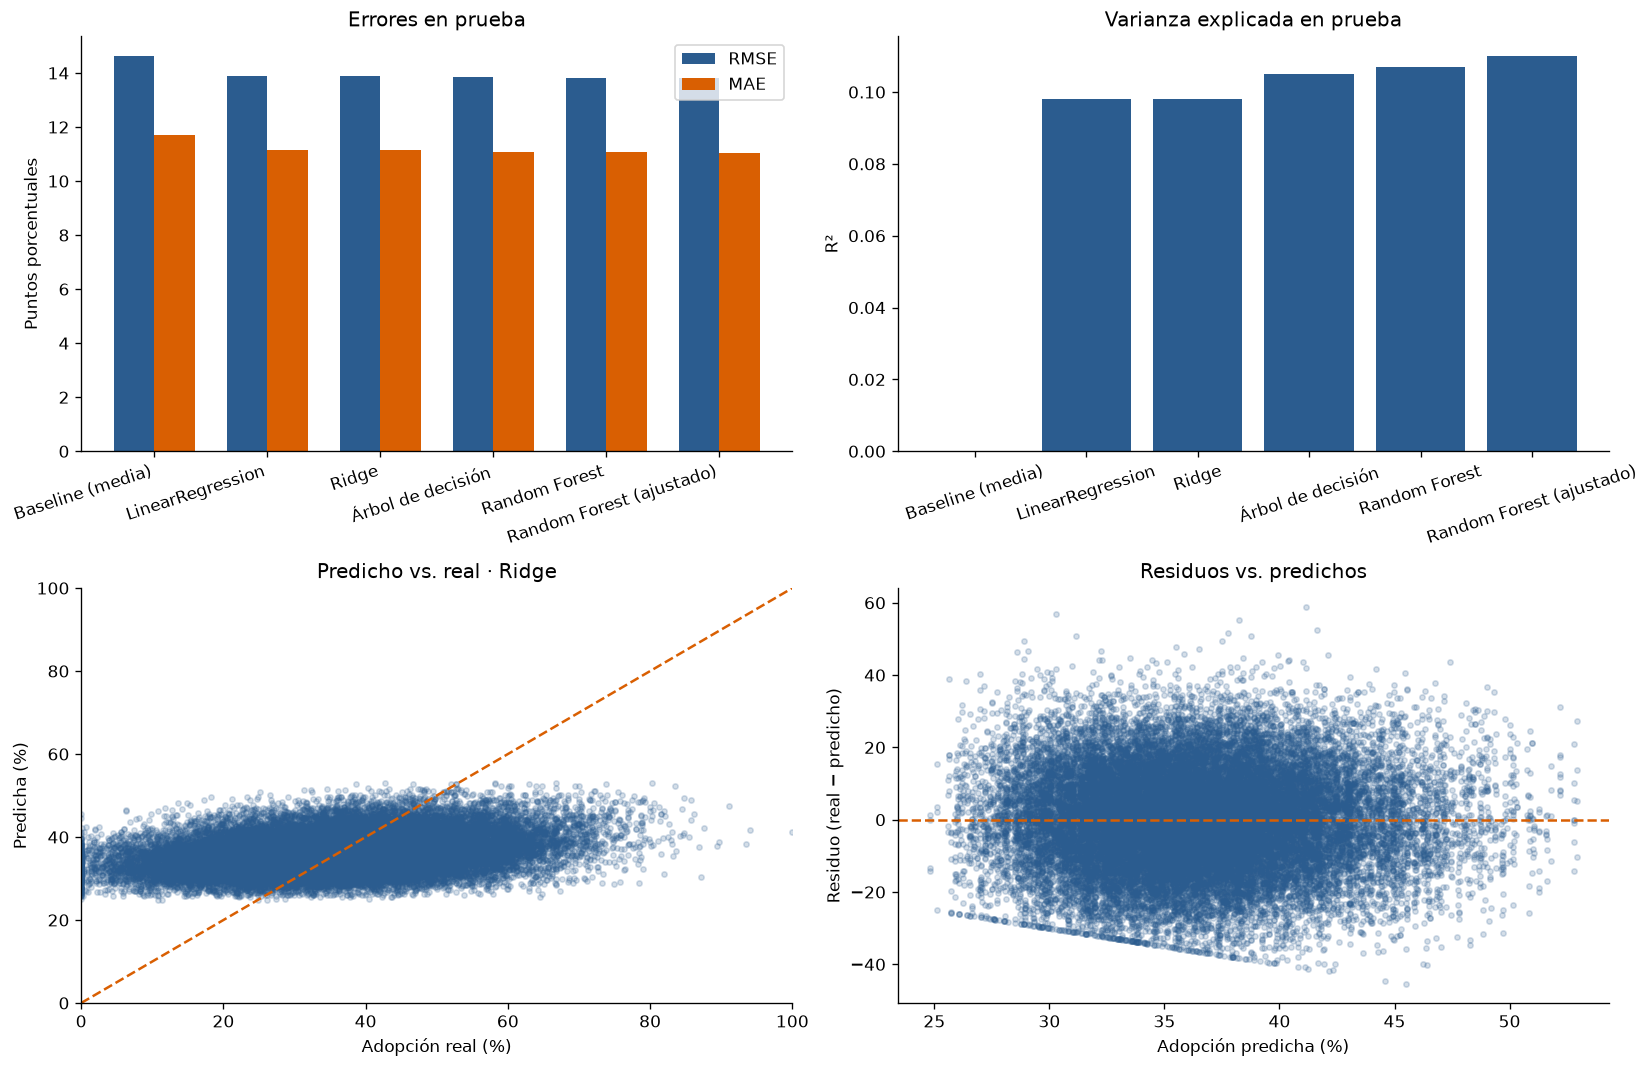

,Tramo,n,predicho_medio,desvio_residuos,sesgo_medio
0,"(24.813, 30.689]",3006,29.093,13.866,0.858
1,"(30.689, 32.428]",3004,31.626,13.970,0.193
2,"(32.428, 33.74]",3000,33.092,13.480,-0.865
3,"(33.74, 34.939]",3005,34.367,13.786,-0.378
4,"(34.939, 36.094]",3001,35.521,13.866,-0.600
5,"(36.094, 37.287]",3004,36.668,13.679,-0.347
6,"(37.287, 38.58]",3004,37.925,14.622,-0.601
7,"(38.58, 40.198]",3002,39.334,13.870,0.421
8,"(40.198, 42.474]",3005,41.231,13.844,0.303
9,"(42.474, 52.912]",3000,45.038,13.780,0.134


Razón entre mayor y menor desvío residual por tramo: 1.08; un valor alejado de 1 sugiere dispersión no constante.


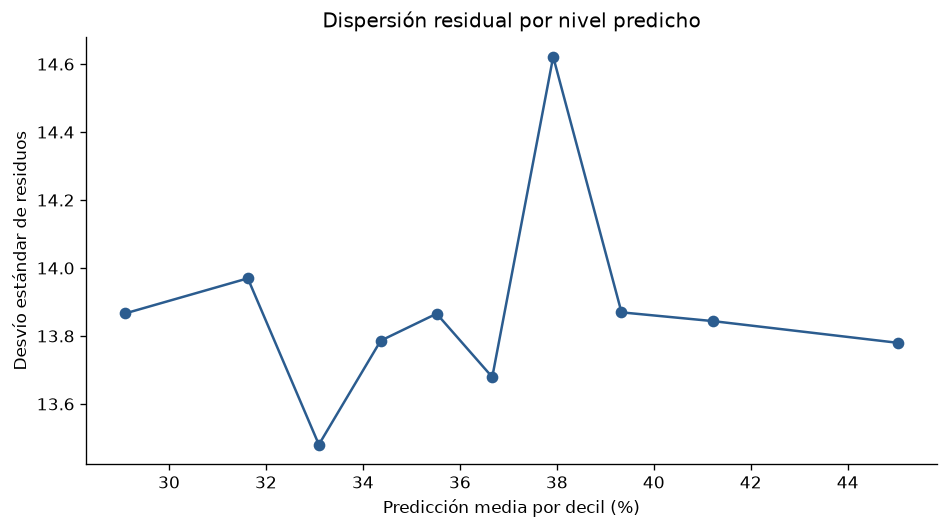

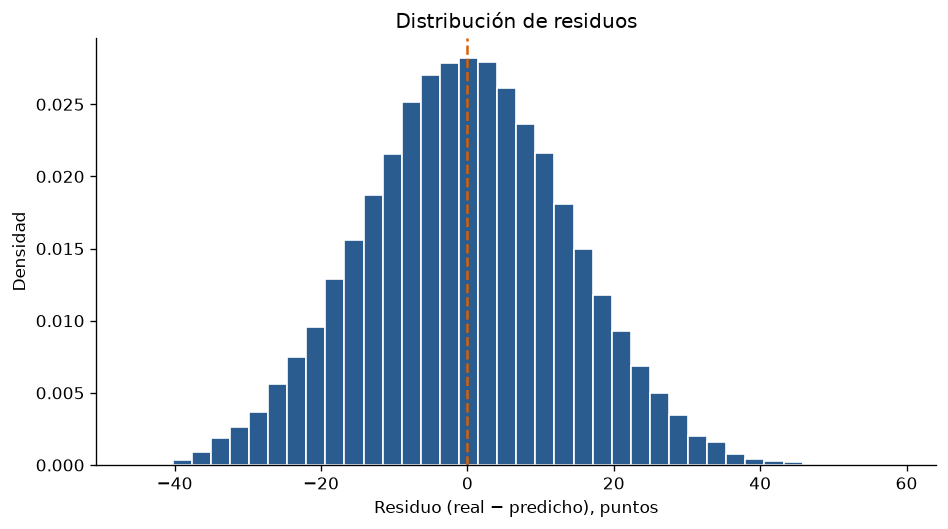

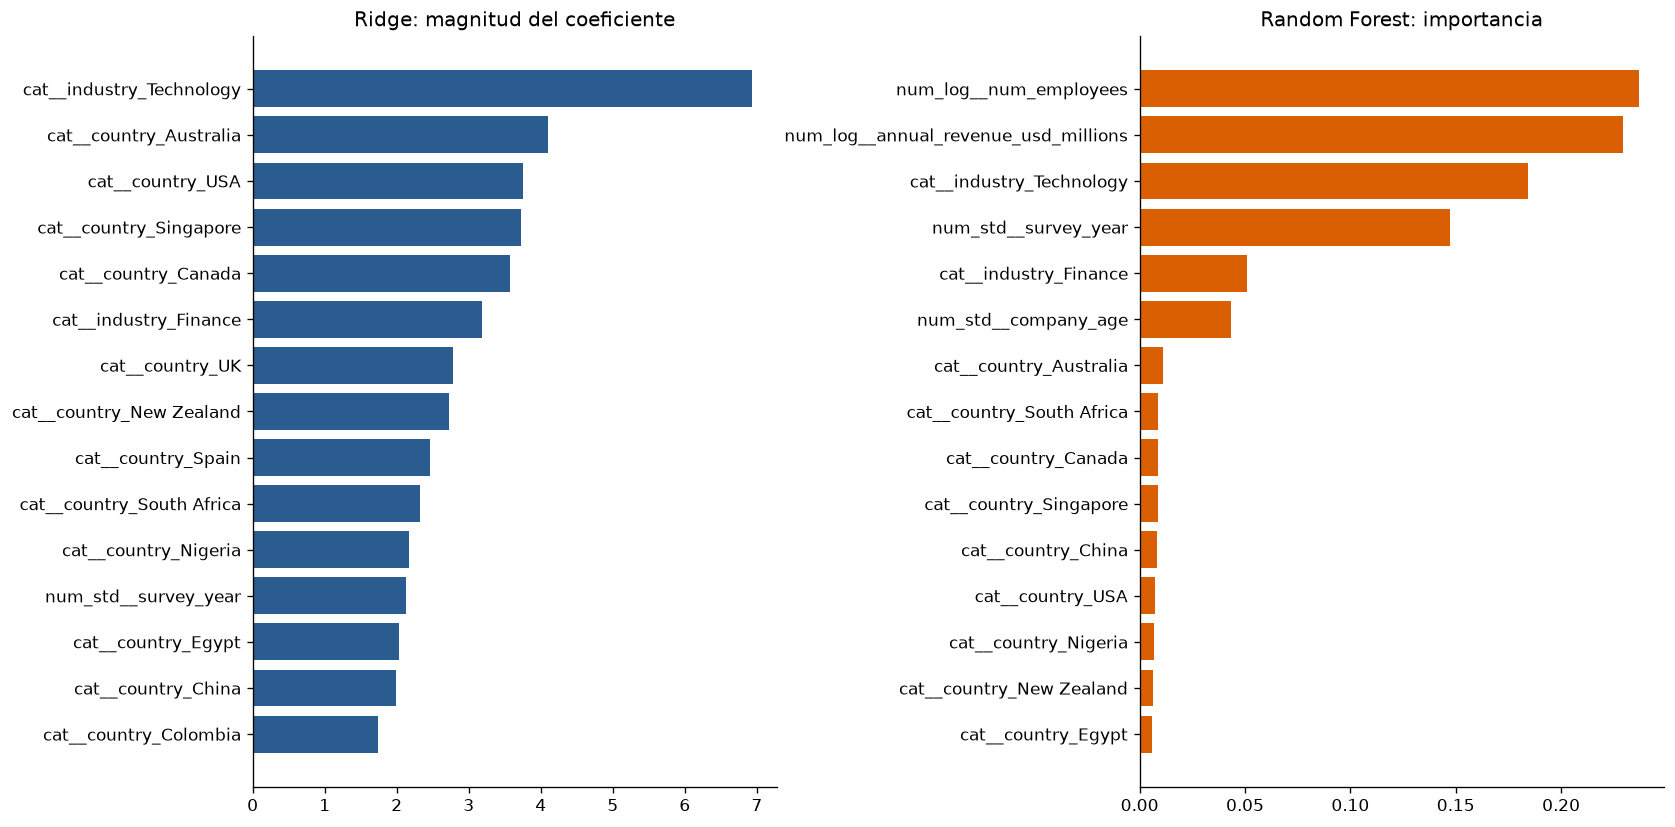

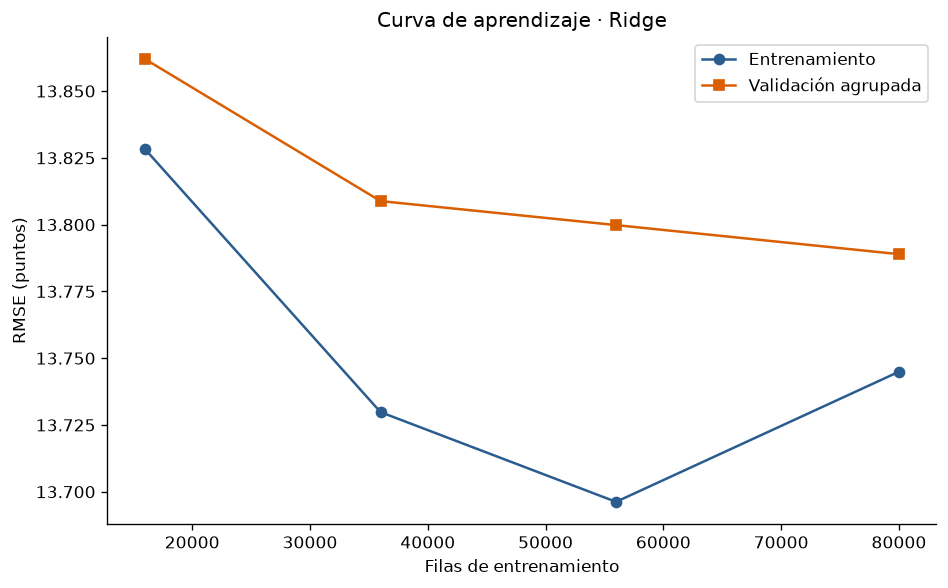

D’Agostino-Pearson en 5,000 residuos: estadístico=7.130, p=0.0283.
La prueba es diagnóstica y no determina por sí sola si el modelo es útil; con muchas observaciones puede detectar desvíos pequeños.


In [6]:
# Comparación gráfica de test y diagnósticos del modelo seleccionado por GroupKFold.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
x = np.arange(len(df_comparativa)); ancho = 0.36
axes[0, 0].bar(x-ancho/2, df_comparativa["RMSE (Test)"], ancho, label="RMSE", color=COLOR_BASE)
axes[0, 0].bar(x+ancho/2, df_comparativa["MAE (Test)"], ancho, label="MAE", color=COLOR_LINEA)
axes[0, 0].set(title="Errores en prueba", ylabel="Puntos porcentuales")
axes[0, 0].set_xticks(x, df_comparativa["Modelo"], rotation=18, ha="right"); axes[0, 0].legend()
axes[0, 1].bar(df_comparativa["Modelo"], df_comparativa["R² (Test)"], color=COLOR_BASE)
axes[0, 1].set(title="Varianza explicada en prueba", ylabel="R²"); axes[0, 1].tick_params(axis="x", rotation=18)

y_test_pred = modelo_seleccionado.predict(X_test)
residuos = y_test.to_numpy() - y_test_pred
axes[1, 0].scatter(y_test, y_test_pred, alpha=.2, color=COLOR_BASE, s=10)
axes[1, 0].plot([0, 100], [0, 100], "--", color=COLOR_LINEA)
axes[1, 0].set(xlabel="Adopción real (%)", ylabel="Predicha (%)", title=f"Predicho vs. real · {mejor_nombre}", xlim=(0,100), ylim=(0,100))
axes[1, 1].scatter(y_test_pred, residuos, alpha=.2, color=COLOR_BASE, s=10)
axes[1, 1].axhline(0, linestyle="--", color=COLOR_LINEA)
axes[1, 1].set(xlabel="Adopción predicha (%)", ylabel="Residuo (real − predicho)", title="Residuos vs. predichos")
plt.tight_layout(); plt.savefig(SALIDAS / "comparativas_y_diagnosticos_tp2.png", dpi=250, bbox_inches="tight"); plt.show()

# Homocedasticidad: comparar la desviación residual entre deciles de predicción.
df_dispersion = pd.DataFrame({"Predicho": y_test_pred, "Residuo": residuos,
    "Tramo": pd.qcut(y_test_pred, q=10, duplicates="drop")})
tabla_dispersion = (df_dispersion.groupby("Tramo", observed=True)
    .agg(n=("Residuo", "size"), predicho_medio=("Predicho", "mean"),
         desvio_residuos=("Residuo", "std"), sesgo_medio=("Residuo", "mean")).reset_index())
display(tabla_dispersion.round(3))
ratio_dispersion = tabla_dispersion["desvio_residuos"].max() / tabla_dispersion["desvio_residuos"].min()
print(f"Razón entre mayor y menor desvío residual por tramo: {ratio_dispersion:.2f}; un valor alejado de 1 sugiere dispersión no constante.")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tabla_dispersion["predicho_medio"], tabla_dispersion["desvio_residuos"], marker="o", color=COLOR_BASE)
ax.set(xlabel="Predicción media por decil (%)", ylabel="Desvío estándar de residuos", title="Dispersión residual por nivel predicho")
plt.tight_layout(); plt.savefig(SALIDAS / "homocedasticidad_tramos_tp2.png", dpi=250, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(residuos, bins=40, color=COLOR_BASE, edgecolor="white", density=True)
ax.axvline(0, color=COLOR_LINEA, linestyle="--")
ax.set(xlabel="Residuo (real − predicho), puntos", ylabel="Densidad", title="Distribución de residuos")
plt.tight_layout(); plt.savefig(SALIDAS / "histograma_residuos_tp2.png", dpi=250, bbox_inches="tight"); plt.show()

# Importancia: magnitud absoluta de Ridge y reducción de impureza de Random Forest.
prep_rf = pipe_rf.named_steps["prepro"]
nombres_features = prep_rf.get_feature_names_out()
coef_ridge = mejor_ridge.named_steps["modelo"].coef_.ravel()
imp = pd.DataFrame({
    "Característica": nombres_features,
    "|Coeficiente Ridge|": np.abs(coef_ridge),
    "Importancia Random Forest": pipe_rf.named_steps["modelo"].feature_importances_,
})
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, col, titulo, color in [(axes[0], "|Coeficiente Ridge|", "Ridge: magnitud del coeficiente", COLOR_BASE),
                              (axes[1], "Importancia Random Forest", "Random Forest: importancia", COLOR_LINEA)]:
    top = imp.nlargest(15, col).sort_values(col)
    ax.barh(top["Característica"], top[col], color=color); ax.set_title(titulo)
plt.tight_layout(); plt.savefig(SALIDAS / "importancia_variables_tp2.png", dpi=250, bbox_inches="tight"); plt.show()

# Curva de aprendizaje por grupos para observar si más datos reducen sesgo o varianza.
tamanos, score_train, score_cv = learning_curve(
    modelo_seleccionado, X_train, y_train, groups=grupos_train,
    train_sizes=[0.2, 0.45, 0.7, 1.0], cv=GroupKFold(n_splits=3),
    scoring="neg_root_mean_squared_error", n_jobs=1,
)
rmse_train_curva, rmse_cv_curva = -score_train.mean(axis=1), -score_cv.mean(axis=1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tamanos, rmse_train_curva, marker="o", label="Entrenamiento", color=COLOR_BASE)
ax.plot(tamanos, rmse_cv_curva, marker="s", label="Validación agrupada", color=COLOR_LINEA)
ax.set(xlabel="Filas de entrenamiento", ylabel="RMSE (puntos)", title=f"Curva de aprendizaje · {mejor_nombre}")
ax.legend(); plt.tight_layout(); plt.savefig(SALIDAS / "curva_aprendizaje_tp2.png", dpi=250, bbox_inches="tight"); plt.show()

# Diagnóstico opcional de normalidad: muestra de hasta 5.000 residuos; con n grande el test es sensible.
rng_residuos = np.random.default_rng(SEMILLA)
residuos_muestra = rng_residuos.choice(residuos, size=min(5_000, len(residuos)), replace=False)
estadistico_norm, p_norm = normaltest(residuos_muestra)
print(f"D’Agostino-Pearson en {len(residuos_muestra):,} residuos: estadístico={estadistico_norm:.3f}, p={p_norm:.3g}.")
print("La prueba es diagnóstica y no determina por sí sola si el modelo es útil; con muchas observaciones puede detectar desvíos pequeños.")

In [7]:
# Exportar el pipeline elegido y una pequeña muestra de empresas del test para la demo.
modelo_regresion_bundle = {
    "model": modelo_seleccionado,
    "features": predictores,
    "target": objetivo,
    "model_name": mejor_nombre,
    "category_options": {
        "country": sorted(df["country"].dropna().astype(str).unique().tolist()),
        "industry": sorted(df["industry"].dropna().astype(str).unique().tolist()),
    },
}
joblib.dump(modelo_regresion_bundle, SALIDAS / "modelo_regresion_tp2.joblib")
filas_test = df.iloc[test_idx].copy()
demo_reg = filas_test.sample(n=min(8, len(filas_test)), random_state=SEMILLA).copy()
demo_reg.insert(0, "demo_id", [f"REG-{i:02d}" for i in range(1, len(demo_reg)+1)])
demo_reg[["demo_id", "company_id", *predictores, objetivo]].to_csv(
    SALIDAS / "muestras_prueba_regresion.csv", index=False
)
print("Guardados: pipeline seleccionado y muestras de prueba de empresas no vistas.")

Guardados: pipeline seleccionado y muestras de prueba de empresas no vistas.


## Interpretación de resultados

GroupKFold seleccionó Ridge, con RMSE 13,793 ± 0,128; LinearRegression obtuvo prácticamente lo mismo (13,795 ± 0,125). En el hold-out, el árbol y los bosques tuvieron errores algo menores, pero las diferencias son pequeñas. El R² de Ridge en test es 0,098: con variables de contexto se explica cerca del 10 % de la variación de la tasa, por lo que la capacidad predictiva global sigue siendo limitada.

La búsqueda del Random Forest eligió profundidad 6. Frente al bosque base, la brecha de RMSE en CV bajó de 0,516 a 0,152; el RMSE de test cambió de 13,815 a 13,798. La mejora es modesta, aunque reduce sobreajuste y el tiempo medio de ajuste por fold del modelo elegido fue 8,62 s, frente a 13,52 s del bosque base. Esa grilla se usa como evidencia de ajuste, no como una comparación independiente del test.

El desvío estándar de los residuos por deciles de predicción tuvo una razón máximo/mínimo de 1,08, sin una variación marcada entre tramos; este diagnóstico no sugiere heterocedasticidad pronunciada. El MAPE de Ridge (66,554 %) excluye las observaciones con objetivo cero, mientras que WAPE (30,668 %) usa todas las filas; por eso no deben leerse como la misma medida ni como error aplicable a casos con adopción cero.

La línea base de la media obtiene RMSE 14,624 y R² aproximadamente 0 en test. El modelo mejora esa referencia, pero la diferencia entre contextos y modelos es pequeña frente a la variabilidad que queda sin explicar. Estos resultados describen el dataset y no implican causalidad ni garantizan generalización a otras poblaciones.